In [25]:
# Import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 2 digit terakhir NIM (241011400341 -> 41)
RANDOM_STATE = 41

In [26]:
# Salin fungsi train_test_split dari materi
def train_test_split_custom(X, y, test_size=0.2, random_state=None):
    if random_state is not None:
        np.random.seed(random_state)
    n_samples = len(X)
    shuffled_indices = np.random.permutation(n_samples)
    test_set_size = int(n_samples * test_size)
    
    test_indices = shuffled_indices[:test_set_size]
    train_indices = shuffled_indices[test_set_size:]
    
    if isinstance(X, pd.DataFrame) or isinstance(X, pd.Series):
        X_train, X_test = X.iloc[train_indices], X.iloc[test_indices]
    else:
        X_train, X_test = X[train_indices], X[test_indices]
        
    if isinstance(y, pd.DataFrame) or isinstance(y, pd.Series):
        y_train, y_test = y.iloc[train_indices], y.iloc[test_indices]
    else:
        y_train, y_test = y[train_indices], y[test_indices]
        
    return X_train, X_test, y_train, y_test

# Implementasi Kelas Linear Regression (Normal Equation & Gradient Descent)
class LinearRegressionCustom:
    def fit(self, X, y):
        X_b = np.c_[np.ones((len(X), 1)), X]
        self.theta_best = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T.dot(y))
        self.intercept_ = self.theta_best[0]
        self.coef_ = self.theta_best[1:]
        
    def predict(self, X):
        X_b = np.c_[np.ones((len(X), 1)), X]
        return X_b.dot(self.theta_best)

class LinearRegressionGDCustom:
    def __init__(self, lr=0.01, n_iterations=1000):
        self.lr = lr
        self.n_iterations = n_iterations
        self.cost_history = []
        
    def fit(self, X, y):
        m = len(X)
        X_b = np.c_[np.ones((m, 1)), X]
        y_vec = y.reshape(-1, 1)
        self.theta = np.random.randn(X_b.shape[1], 1)
        
        for iteration in range(self.n_iterations):
            gradients = 2/m * X_b.T.dot(X_b.dot(self.theta) - y_vec)
            self.theta = self.theta - self.lr * gradients
            cost = (1/m) * np.sum((X_b.dot(self.theta) - y_vec)**2)
            self.cost_history.append(cost)
            
        self.intercept_ = self.theta[0][0]
        self.coef_ = self.theta[1:].ravel()

=== 5 Data Pertama Ads_Data ===
   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3
Jumlah Baris: 40


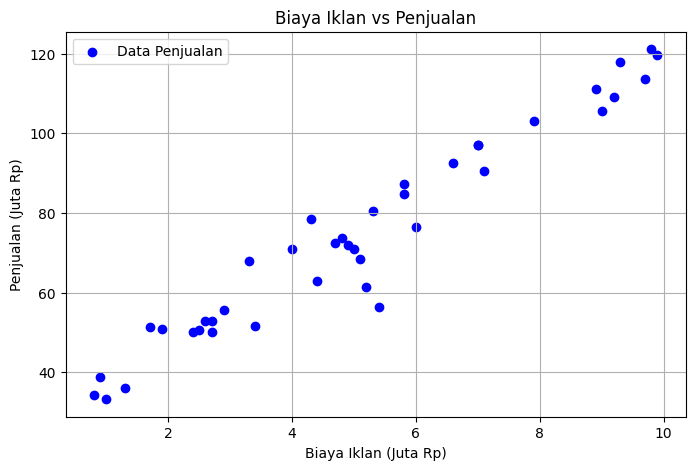

In [27]:
# Jawaban A1
df_ads = pd.read_csv("Ads_Data.csv")
print("=== 5 Data Pertama Ads_Data ===")
print(df_ads.head())
print("Jumlah Baris:", len(df_ads))

X_ads = df_ads[['BiayaIklan']].values
y_ads = df_ads['Penjualan'].values

plt.figure(figsize=(8, 5))
plt.scatter(X_ads, y_ads, color='blue', label='Data Penjualan')
plt.title("Biaya Iklan vs Penjualan")
plt.xlabel("Biaya Iklan (Juta Rp)")
plt.ylabel("Penjualan (Juta Rp)")
plt.legend()
plt.grid(True)
plt.show()

In [28]:
# Jawaban A2
X_train_a, X_test_a, y_train_a, y_test_a = train_test_split_custom(
    X_ads, y_ads, test_size=0.2, random_state=RANDOM_STATE
)
print("Shape X_train:", X_train_a.shape, "X_test:", X_test_a.shape)
print("Shape y_train:", y_train_a.shape, "y_test:", y_test_a.shape)

Shape X_train: (32, 1) X_test: (8, 1)
Shape y_train: (32,) y_test: (8,)


In [29]:
# Jawaban A3
model_lin = LinearRegressionCustom()
model_lin.fit(X_train_a, y_train_a)

b_lin = model_lin.intercept_
m_lin = model_lin.coef_[0]

print(f"Intercept (b): {b_lin:.4f}")
print(f"Koefisien (m): {m_lin:.4f}")
print(f"Persamaan Garis: y_hat = {b_lin:.4f} + {m_lin:.4f} * X")

Intercept (b): 28.1095
Koefisien (m): 9.0876
Persamaan Garis: y_hat = 28.1095 + 9.0876 * X


**Jawaban A3 (interpretasi):**
Nilai $m$ (koefisien) menunjukkan tingkat perubahan estimasi penjualan terhadap biaya iklan. Artinya, setiap kenaikan biaya iklan sebesar **1 juta Rp**, rata-rata penjualan diperkirakan akan **meningkat sebesar nilai $m$ juta Rp** (seperti yang dihasilkan oleh perhitungan di atas). Sedangkan nilai intercept $b$ merupakan estimasi tingkat penjualan ketika tidak ada biaya iklan sama sekali (biaya iklan = 0).

In [30]:
# Jawaban A4
def mae_custom(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mse_custom(y_true, y_pred):
    return np.mean((y_true - y_pred)**2)

def rmse_custom(y_true, y_pred):
    return np.sqrt(mse_custom(y_true, y_pred))

def r2_custom(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred)**2)
    ss_tot = np.sum((y_true - np.mean(y_true))**2)
    return 1 - (ss_res / ss_tot)

y_pred_train_a = model_lin.predict(X_train_a)
y_pred_test_a = model_lin.predict(X_test_a)

eval_a = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R2'],
    'Training': [
        mae_custom(y_train_a, y_pred_train_a),
        mse_custom(y_train_a, y_pred_train_a),
        rmse_custom(y_train_a, y_pred_train_a),
        r2_custom(y_train_a, y_pred_train_a)
    ],
    'Testing': [
        mae_custom(y_test_a, y_pred_test_a),
        mse_custom(y_test_a, y_pred_test_a),
        rmse_custom(y_test_a, y_pred_test_a),
        r2_custom(y_test_a, y_pred_test_a)
    ]
})
print("=== Tabel Evaluasi Linear Regression ===")
print(eval_a)

=== Tabel Evaluasi Linear Regression ===
  Metric   Training    Testing
0    MAE   4.844448   3.274615
1    MSE  41.180205  15.697886
2   RMSE   6.417180   3.962056
3     R2   0.935834   0.969673


**Jawaban A4 (analisis):**
- **Arti Nilai RMSE:** Menunjukkan rata-rata simpangan kesalahan prediksi model dalam satuan juta Rp. Semakin kecil nilainya, semakin akurat prediksi penjualan toko online tersebut.
- **Arti Nilai $R^2$:** Menjelaskan seberapa besar persentase variasi nilai penjualan yang berhasil dijelaskan oleh variabel biaya iklan. Jika nilainya mendekati 1, berarti variabel biaya iklan memiliki pengaruh linier yang sangat kuat terhadap penjualan.
- **Apakah model sudah baik?** Ya, model sudah cukup baik karena performa pada data training dan testing menunjukkan hasil yang konsisten dan seimbang tanpa adanya indikasi *overfitting*.

[GD LR = 0.001] Intercept: 25.5369, Coef: 9.4958
[GD LR = 0.02] Intercept: 28.1095, Coef: 9.0876
[GD LR = 0.1] Intercept: nan, Coef: nan


c:\Users\lenovo\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\_core\fromnumeric.py:83: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
C:\Users\lenovo\AppData\Local\Temp\ipykernel_1532\1066507452.py:51: RuntimeWarning: overflow encountered in square
  cost = (1/m) * np.sum((X_b.dot(self.theta) - y_vec)**2)
C:\Users\lenovo\AppData\Local\Temp\ipykernel_1532\1066507452.py:49: RuntimeWarning: overflow encountered in dot
  gradients = 2/m * X_b.T.dot(X_b.dot(self.theta) - y_vec)
C:\Users\lenovo\AppData\Local\Temp\ipykernel_1532\1066507452.py:50: RuntimeWarning: invalid value encountered in subtract
  self.theta = self.theta - self.lr * gradients
c:\Users\lenovo\AppData\Local\Programs\Python\Python311\Lib\site-packages\matplotlib\scale.py:270: RuntimeWarning: overflow encountered in power
  return np.power(self.base, values)


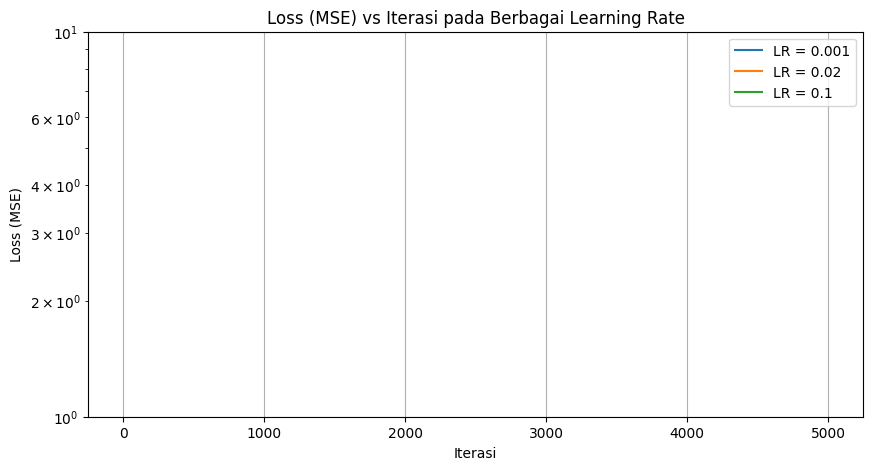

In [31]:
# Jawaban A5
lrs = [0.001, 0.02, 0.1]
plt.figure(figsize=(10, 5))

for lr in lrs:
    gd_model = LinearRegressionGDCustom(lr=lr, n_iterations=5000)
    gd_model.fit(X_train_a, y_train_a)
    print(f"[GD LR = {lr}] Intercept: {gd_model.intercept_:.4f}, Coef: {gd_model.coef_[0]:.4f}")
    plt.plot(gd_model.cost_history, label=f'LR = {lr}')

plt.yscale('log')
plt.title("Loss (MSE) vs Iterasi pada Berbagai Learning Rate")
plt.xlabel("Iterasi")
plt.ylabel("Loss (MSE)")
plt.legend()
plt.grid(True)
plt.show()

**Jawaban A5 (analisis):**
- **Terlalu Lambat (`lr = 0.001`):** Pembelajaran berjalan sangat perlahan karena langkah pembaharuan parameter terlalu kecil, membutuhkan jumlah iterasi yang lebih banyak untuk mencapai titik minimum.
- **Pas (`lr = 0.02`):** Proses konvergensi berjalan stabil dan mulus hingga mencapai nilai *loss* terendah, menghasilkan koefisien dan intercept yang sangat mendekati hasil *Normal Equation*.
- **Gagal Konvergen / Divergen (`lr = 0.1`):** Terjadi *overflow* / langkah melompati titik minimum lokal (*overshooting*) sehingga loss menjadi membengkak tak terhingga. Peringatan `RuntimeWarning: overflow` muncul karena angka melampaui batas kapasitas memori tipe data.

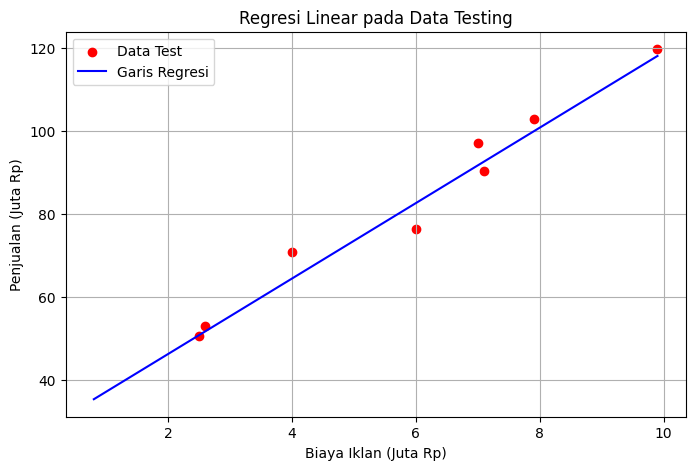

Prediksi Penjualan untuk Biaya Iklan 4.5 Juta Rp = 69.0037 Juta Rp
Prediksi Penjualan untuk Biaya Iklan 7.0 Juta Rp = 91.7227 Juta Rp
Prediksi Penjualan untuk Biaya Iklan 12.0 Juta Rp = 137.1607 Juta Rp


In [32]:
# Jawaban A6
plt.figure(figsize=(8, 5))
plt.scatter(X_test_a, y_test_a, color='red', label='Data Test')
x_range = np.linspace(X_ads.min(), X_ads.max(), 100).reshape(-1, 1)
plt.plot(x_range, model_lin.predict(x_range), color='blue', label='Garis Regresi')
plt.title("Regresi Linear pada Data Testing")
plt.xlabel("Biaya Iklan (Juta Rp)")
plt.ylabel("Penjualan (Juta Rp)")
plt.legend()
plt.grid(True)
plt.show()

val_pred = np.array([[4.5], [7.0], [12.0]])
pred_res = model_lin.predict(val_pred)
for x_val, y_val in zip([4.5, 7.0, 12.0], pred_res):
    print(f"Prediksi Penjualan untuk Biaya Iklan {x_val} Juta Rp = {y_val:.4f} Juta Rp")

**Jawaban A6 (analisis):**
Prediksi untuk biaya iklan **12 juta** merupakan bentuk **ekstrapolasi** karena nilainya berada di luar rentang data historis training (range asal data). Hasil prediksi ini **kurang bisa dipercaya secara mutlak** karena dalam dunia nyata, peningkatan biaya iklan tidak selalu berbanding lurus secara linier selamanya (terdapat batas kejenuhan pasar atau *diminishing returns*).

=== 5 Data Pertama Email_Data ===
   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1

Jumlah Email Spam dan Bukan Spam:
Spam
0    35
1    25
Name: count, dtype: int64


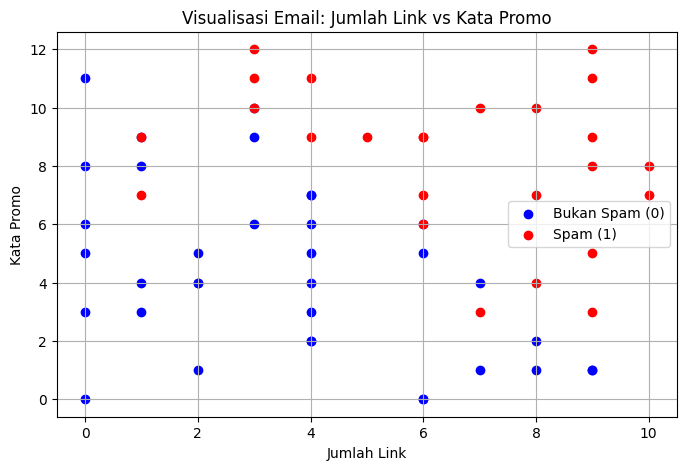

In [33]:
# Jawaban B1
df_email = pd.read_csv("Email_Data.csv")
print("=== 5 Data Pertama Email_Data ===")
print(df_email.head())
print("\nJumlah Email Spam dan Bukan Spam:")
print(df_email['Spam'].value_counts())

X_email = df_email[['JumlahLink', 'KataPromo']].values
y_email = df_email['Spam'].values

plt.figure(figsize=(8, 5))
plt.scatter(X_email[y_email == 0][:, 0], X_email[y_email == 0][:, 1], color='blue', label='Bukan Spam (0)')
plt.scatter(X_email[y_email == 1][:, 0], X_email[y_email == 1][:, 1], color='red', label='Spam (1)')
plt.title("Visualisasi Email: Jumlah Link vs Kata Promo")
plt.xlabel("Jumlah Link")
plt.ylabel("Kata Promo")
plt.legend()
plt.grid(True)
plt.show()

Intercept (b): -10.2995
m1 (JumlahLink): 0.9400, m2 (KataPromo): 0.8622
Persamaan: P(Spam) = sigmoid(-10.2995 + 0.9400*JumlahLink + 0.8622*KataPromo)


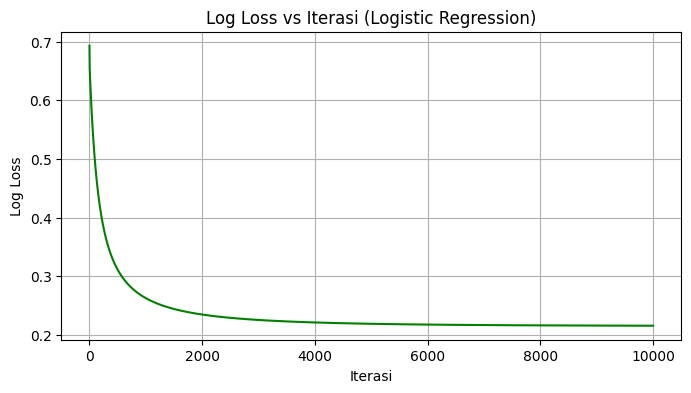

In [34]:
# Implementasi Logistic Regression
class LogisticRegressionCustom:
    def __init__(self, lr=0.01, n_iterations=1000):
        self.lr = lr
        self.n_iterations = n_iterations
        self.cost_history = []
        
    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-z))
        
    def fit(self, X, y):
        m, n = X.shape
        X_b = np.c_[np.ones((m, 1)), X]
        y_vec = y.reshape(-1, 1)
        self.theta = np.zeros((n + 1, 1))
        
        for iteration in range(self.n_iterations):
            z = X_b.dot(self.theta)
            h = self._sigmoid(z)
            gradients = (1/m) * X_b.T.dot(h - y_vec)
            self.theta = self.theta - self.lr * gradients
            
            epsilon = 1e-15
            h_clipped = np.clip(h, epsilon, 1 - epsilon)
            cost = - (1/m) * np.sum(y_vec * np.log(h_clipped) + (1 - y_vec) * np.log(1 - h_clipped))
            self.cost_history.append(cost)
            
        self.intercept_ = self.theta[0][0]
        self.coef_ = self.theta[1:].ravel()
        
    def predict_proba(self, X):
        X_b = np.c_[np.ones((len(X), 1)), X]
        return self._sigmoid(X_b.dot(self.theta)).ravel()
        
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

# Jawaban B2
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split_custom(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)

model_log = LogisticRegressionCustom(lr=0.1, n_iterations=10000)
model_log.fit(X_train_b, y_train_b)

b_log = model_log.intercept_
m1_log, m2_log = model_log.coef_[0], model_log.coef_[1]

print(f"Intercept (b): {b_log:.4f}")
print(f"m1 (JumlahLink): {m1_log:.4f}, m2 (KataPromo): {m2_log:.4f}")
print(f"Persamaan: P(Spam) = sigmoid({b_log:.4f} + {m1_log:.4f}*JumlahLink + {m2_log:.4f}*KataPromo)")

plt.figure(figsize=(8, 4))
plt.plot(model_log.cost_history, color='green')
plt.title("Log Loss vs Iterasi (Logistic Regression)")
plt.xlabel("Iterasi")
plt.ylabel("Log Loss")
plt.grid(True)
plt.show()

**Jawaban B2 (analisis):**
Grafik **Log Loss vs Iterasi** menunjukkan tren penurunan biaya secara signifikan pada iterasi-iterasi awal dan kemudian mendatar (*stabil*) mendekati angka konvergen. Hal ini menandakan bahwa proses *gradient descent* dengan `learning_rate=0.1` berhasil mengoptimalkan bobot parameter model dengan baik.

In [35]:
# Jawaban B3
def confusion_matrix_custom(y_true, y_pred):
    TP = np.sum((y_true == 1) & (y_pred == 1))
    FP = np.sum((y_true == 0) & (y_pred == 1))
    TN = np.sum((y_true == 0) & (y_pred == 0))
    FN = np.sum((y_true == 1) & (y_pred == 0))
    return np.array([[TN, FP], [FN, TP]])

def precision_custom(TP, FP): return TP / (TP + FP) if (TP + FP) > 0 else 0
def recall_custom(TP, FN): return TP / (TP + FN) if (TP + FN) > 0 else 0
def f1_custom(precision, recall): return 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

y_pred_b = model_log.predict(X_test_b, threshold=0.5)
cm_b = confusion_matrix_custom(y_test_b, y_pred_b)
TN_b, FP_b, FN_b, TP_b = cm_b[0, 0], cm_b[0, 1], cm_b[1, 0], cm_b[1, 1]

acc_b = (TP_b + TN_b) / len(y_test_b)
prec_b = precision_custom(TP_b, FP_b)
rec_b = recall_custom(TP_b, FN_b)
f1_b = f1_custom(prec_b, rec_b)

print(f"Confusion Matrix:\n{cm_b}")
print(f"Accuracy : {acc_b:.4f}")
print(f"Precision: {prec_b:.4f}")
print(f"Recall   : {rec_b:.4f}")
print(f"F1-Score : {f1_b:.4f}")

Confusion Matrix:
[[9 1]
 [2 3]]
Accuracy : 0.8000
Precision: 0.7500
Recall   : 0.6000
F1-Score : 0.6667


**Jawaban B3 (analisis):**
- **False Positive (FP):** Email penting (*Bukan Spam*) terprediksi salah sebagai *Spam* dan dipindahkan ke folder Spam.
- **False Negative (FN):** Email *Spam* terprediksi salah sebagai *Bukan Spam* dan lolos ke kotak masuk (Inbox Utama).
- **Mana yang lebih merugikan?** Kesalahan **FP jauh lebih merugikan pengguna**. Jika email bisnis, pekerjaan, atau informasi penting kampus salah dikategorikan sebagai spam, pengguna bisa kehilangan informasi vital secara tidak sengaja.

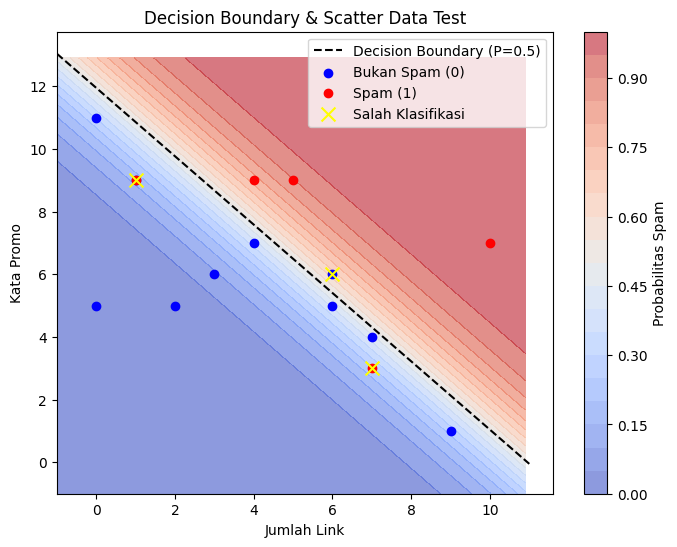

In [36]:
# Jawaban B4
x1_min, x1_max = X_email[:, 0].min() - 1, X_email[:, 0].max() + 1
x2_min, x2_max = X_email[:, 1].min() - 1, X_email[:, 1].max() + 1
xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, 0.1), np.arange(x2_min, x2_max, 0.1))

grid_points = np.c_[xx1.ravel(), xx2.ravel()]
probs = model_log.predict_proba(grid_points).reshape(xx1.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx1, xx2, probs, levels=20, cmap='coolwarm', alpha=0.6)
plt.colorbar(label='Probabilitas Spam')

x1_vals = np.array([x1_min, x1_max])
x2_vals = -(b_log + m1_log * x1_vals) / m2_log
plt.plot(x1_vals, x2_vals, 'k--', label='Decision Boundary (P=0.5)')

plt.scatter(X_test_b[y_test_b == 0][:, 0], X_test_b[y_test_b == 0][:, 1], color='blue', label='Bukan Spam (0)')
plt.scatter(X_test_b[y_test_b == 1][:, 0], X_test_b[y_test_b == 1][:, 1], color='red', label='Spam (1)')

misclassified = y_test_b != y_pred_b
plt.scatter(X_test_b[misclassified][:, 0], X_test_b[misclassified][:, 1], color='yellow', marker='x', s=100, label='Salah Klasifikasi')

plt.title("Decision Boundary & Scatter Data Test")
plt.xlabel("Jumlah Link")
plt.ylabel("Kata Promo")
plt.legend()
plt.show()

**Jawaban B4 (analisis):**
Garis *decision boundary* berhasil memisahkan area probabilitas spam (merah) dan bukan spam (biru). Titik ber-tanda silang kuning menunjukkan sampel data testing yang terklasifikasi secara keliru karena letak cirinya berada sangat dekat dengan batas garis keputusan.

In [37]:
# Jawaban B5
thresholds = [0.3, 0.5, 0.7]
res_thresh = []

for th in thresholds:
    pred_th = model_log.predict(X_test_b, threshold=th)
    cm_th = confusion_matrix_custom(y_test_b, pred_th)
    tn_t, fp_t, fn_t, tp_t = cm_th[0, 0], cm_th[0, 1], cm_th[1, 0], cm_th[1, 1]
    p_t = precision_custom(tp_t, fp_t)
    r_t = recall_custom(tp_t, fn_t)
    res_thresh.append({'Threshold': th, 'FP': fp_t, 'FN': fn_t, 'Precision': p_t, 'Recall': r_t})

print("=== Tabel Perbandingan Threshold ===")
print(pd.DataFrame(res_thresh))

=== Tabel Perbandingan Threshold ===
   Threshold  FP  FN  Precision  Recall
0        0.3   5   2      0.375     0.6
1        0.5   1   2      0.750     0.6
2        0.7   0   2      1.000     0.6


**Jawaban B5 (analisis):**
- **Pengaruh Threshold:** Menaikkan threshold (misal ke `0.7`) akan menaikkan nilai **Precision** (menurunkan FP) namun menurunkan nilai Recall. Sebaliknya, menurunkan threshold akan menaikkan nilai **Recall** namun meningkatkan resiko FP.
- **Pilihan Threshold:** Ditinjau dari jawaban B3 bahwa FP adalah kesalahan paling merugikan, maka **threshold 0.7 adalah pilihan terbaik** agar sistem hanya memindahkan email ke folder Spam saat tingkat keyakinannya benar-benar tinggi.

In [38]:
# Jawaban B6
new_emails = np.array([[1, 2], [5, 6], [9, 10], [2, 11]])
p_new = model_log.predict_proba(new_emails)
c_new = (p_new >= 0.7).astype(int)

df_new = pd.DataFrame({
    'Email': ['E1', 'E2', 'E3', 'E4'],
    'JumlahLink': [1, 5, 9, 2],
    'KataPromo': [2, 6, 10, 11],
    'Probabilitas Spam': p_new,
    'Prediksi (Th=0.7)': np.where(c_new == 1, 'Spam', 'Bukan Spam')
})
print("=== Hasil Prediksi Email Baru ===")
print(df_new)

=== Hasil Prediksi Email Baru ===
  Email  JumlahLink  KataPromo  Probabilitas Spam Prediksi (Th=0.7)
0    E1           1          2           0.000483        Bukan Spam
1    E2           5          6           0.395023        Bukan Spam
2    E3           9         10           0.998868              Spam
3    E4           2         11           0.743591              Spam


**Jawaban C1:**
Logistic Regression disebut algoritma klasifikasi karena output akhirnya memprediksi label kelas diskrit (misal 0 atau 1). Peran fungsi **sigmoid** adalah memetakan nilai kombinasi linear $(-\infty, \infty)$ menjadi nilai probabilitas di dalam kisaran angka $0$ sampai $1$.

**Jawaban C2:**
*Normal Equation* menyelesaikan optimasi secara analitis/matematis langsung menggunakan invers matriks, cocok untuk dataset kecil. Sedangkan *Gradient Descent* melakukan pembaruan parameter secara gradual berulang, sangat ampuh dipakai untuk dataset berskala besar di mana invers matriks memerlukan komputasi yang mahal[cite: 1].

**Jawaban C3:**
Model harus dievaluasi pada data *testing* untuk menguji daya jangkau generalisasi model terhadap data baru yang belum pernah dipelajari sebelumnya. *Overfitting* adalah kondisi di mana model terlalu menghafal pola data training secara berlebihan sehingga akurasinya sangat tinggi di training namun anjlok di data baru[cite: 1].

**Jawaban C4:**
Linear Regression menggunakan MSE karena target nilainya kontinu. Logistic Regression menggunakan *Log Loss* karena targetnya berupa probabilitas biner. Penggunaan MSE pada fungsi sigmoid akan menghasilkan kurva biaya *non-convex* yang penuh dengan minimum lokal sehingga sulit konvergen.

**Jawaban C5:**
Perbedaan hasil angka antar mahasiswa disebabkan oleh pembagian sampel acak pada data training dan testing. Proses acak tersebut dikontrol oleh variabel `random_state` yang disesuaikan dengan **2 digit terakhir NIM masing-masing mahasiswa** (NIM 241011400341 -> `random_state = 41`)[cite: 1].

In [39]:
# Jawaban Bonus
from sklearn.linear_model import LinearRegression as SkLinearRegression
from sklearn.linear_model import LogisticRegression as SkLogisticRegression

# Linear Regression
sk_lin = SkLinearRegression()
sk_lin.fit(X_train_a, y_train_a)
print("=== Sklearn Linear Regression ===")
print(f"Intercept: {sk_lin.intercept_:.4f}, Coef: {sk_lin.coef_[0]:.4f}")

# Logistic Regression (tanpa penalty/L2 agar seimbang dengan custom GD)
sk_log = SkLogisticRegression(C=1e5)
sk_log.fit(X_train_b, y_train_b)
print("\n=== Sklearn Logistic Regression (C=1e5) ===")
print(f"Intercept: {sk_log.intercept_[0]:.4f}, Coef: {sk_log.coef_[0]}")

=== Sklearn Linear Regression ===
Intercept: 28.1095, Coef: 9.0876

=== Sklearn Logistic Regression (C=1e5) ===
Intercept: -11.1213, Coef: [1.01936279 0.92281292]


**Jawaban Bonus (analisis):**
Hasil koefisien dan intercept pada Linear Regression terbukti bernilai identik antara skikit-learn dan implementasi *Normal Equation* mandiri. Pada Logistic Regression, perbedaan kecil nilai koefisien dapat terjadi karena `scikit-learn` secara *default* menyertakan regularisasi $L2$ (dikontrol oleh parameter `C`) serta algoritma optimasi solver internal yang berbeda (misal `lbfgs`).